# Business Problem

A regional hotel chain with properties in five Indian cities wants to understand what drives guest satisfaction. The revenue manager needs to know which booking and stay factors move the satisfaction score, and which bookings are at risk of unhappy guests, so the chain can improve service and protect repeat business.

# Questions

1) What does the guest satisfaction score look like overall? Look at the average, the lowest and highest values, and how the scores are spread out.

2) Do Room_Rate_INR and Meal_Spend_INR affect the satisfaction score? Check whether higher rates or higher meal spending go with higher or lower scores.

3) Does the score differ by Hotel_City, Room_Type, Booking_Channel and Customer_Type? Compare the average score across the groups in each of these columns.

4) Which bookings need attention? Label a booking “At Risk” if its Guest_Satisfaction_Score is below 5.5, then see how many there are and what they have in common.

## Load and Inspect

In [15]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/hotel_bookings_data.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["Hotel_City"].value_counts())

  Booking_ID Hotel_City Room_Type Booking_Channel Customer_Type  \
0      H1190     Jaipur    Deluxe         Walk_In        Family   
1      H1062        Goa  Standard    Travel_Agent    Individual   
2      H1097  Bengaluru  Standard    Travel_Agent        Family   
3      H1070      Delhi    Deluxe    Travel_Agent        Family   
4      H1041  Bengaluru    Deluxe      Mobile_App           NaN   

   Lead_Time_Days  Stay_Nights  Num_Guests  Room_Rate_INR  Meal_Spend_INR  \
0            18.0            4           4           4800          1000.0   
1            23.0            3           3           3800           790.0   
2            31.0            2           4           2650           770.0   
3            52.0            3           4           5700           740.0   
4            14.0            3           4           6100          1450.0   

  Check_In_Date  Guest_Satisfaction_Score  
0    2025-11-30                       7.2  
1    2025-11-28                       5.6  
2 

## Cleaning

In [16]:
print("Duplicates found:", df.duplicated().sum())
df = df.drop_duplicates()
print(f"Number of duplicates: {df.duplicated().sum()}\n")

df["Hotel_City"] = df["Hotel_City"].str.strip().str.title()
print(df["Hotel_City"].value_counts(), "\n")

print("Bad Stay_Nights rows:", (df["Stay_Nights"] < 1).sum(), "\n")
df.loc[df["Stay_Nights"] < 1, "Stay_Nights"] = np.nan

df["Stay_Nights"] = df["Stay_Nights"].fillna(df["Stay_Nights"].median())
df["Lead_Time_Days"] = df["Lead_Time_Days"].fillna(df["Lead_Time_Days"].median())
df["Meal_Spend_INR"] = df["Meal_Spend_INR"].fillna(df["Meal_Spend_INR"].median())

df["Customer_Type"] = df["Customer_Type"].fillna(df["Customer_Type"].mode()[0])
df["Booking_Channel"] = df["Booking_Channel"].fillna(df["Booking_Channel"].mode()[0])

print(df.isnull().sum(), "\n")
print(df.describe(), "\n")
print(df.shape)

df = df.reset_index(drop=True)
df.to_csv("../data/processed/hotel_bookings_clean.csv", index=False)

Duplicates found: 5
Number of duplicates: 0

Hotel_City
Mumbai       79
Bengaluru    57
Delhi        56
Goa          36
Jaipur       22
Name: count, dtype: int64 

Bad Stay_Nights rows: 2 

Booking_ID                  0
Hotel_City                  0
Room_Type                   0
Booking_Channel             0
Customer_Type               0
Lead_Time_Days              0
Stay_Nights                 0
Num_Guests                  0
Room_Rate_INR               0
Meal_Spend_INR              0
Check_In_Date               0
Guest_Satisfaction_Score    0
dtype: int64 

       Lead_Time_Days  Stay_Nights  Num_Guests  Room_Rate_INR  Meal_Spend_INR  \
count      250.000000   250.000000   250.00000     250.000000      250.000000   
mean        29.224000     3.132000     2.57600    4999.200000     1247.560000   
std         20.832229     1.315102     1.18399    2178.661429      482.580961   
min          1.000000     1.000000     1.00000    2000.000000        0.000000   
25%         14.250000     2.00

## Creating Column

In [22]:
df["Total_Room_Revenue"] = df["Room_Rate_INR"] * df["Stay_Nights"]

df["Risk_Flag"] = np.where(df["Guest_Satisfaction_Score"] < 5.5, "At Risk", "OK")

df["Lead_Time_Band"] = pd.cut(
    df["Lead_Time_Days"],
    bins=[-1, 7, 30, 90, 180],
    labels=["Last-minute", "Short", "Planned", "Early"]
)

print(df[["Total_Room_Revenue", "Risk_Flag", "Lead_Time_Band"]].head(), "\n")
print(df["Risk_Flag"].value_counts(), "\n")
print(df["Lead_Time_Band"].value_counts(), "\n")

   Total_Room_Revenue Risk_Flag Lead_Time_Band
0             19200.0        OK          Short
1             11400.0        OK          Short
2              5300.0        OK        Planned
3             17100.0   At Risk        Planned
4             18300.0        OK          Short 

Risk_Flag
OK         215
At Risk     35
Name: count, dtype: int64 

Lead_Time_Band
Short          137
Planned         87
Last-minute     21
Early            5
Name: count, dtype: int64 



## What does the guest satisfaction score look like overall? Look at the average, the lowest and highest values, and how the scores are spread out.

count    250.000000
mean       6.834000
std        1.338976
min        3.400000
25%        5.900000
50%        6.800000
75%        7.600000
max       10.000000
Name: Guest_Satisfaction_Score, dtype: float64


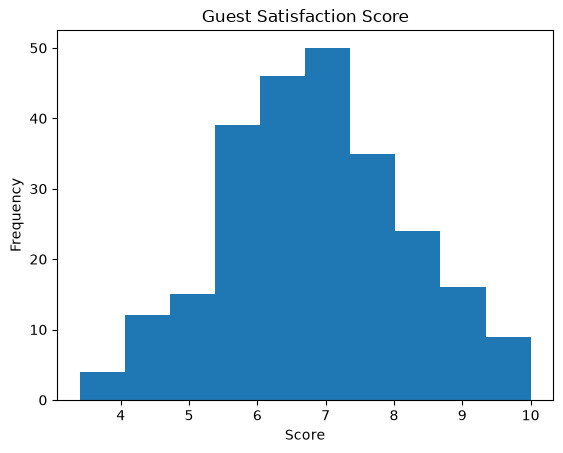

In [18]:
import matplotlib.pyplot as plt

print(df["Guest_Satisfaction_Score"].describe())

df["Guest_Satisfaction_Score"].plot(kind="hist", bins=10)
plt.title("Guest Satisfaction Score")
plt.xlabel("Score")
plt.savefig("../images/q1_score_distribution.png")
plt.show()

## Do Room_Rate_INR and Meal_Spend_INR affect the satisfaction score? Check whether higher rates or higher meal spending go with higher or lower scores.

0.5891323000489496
0.5387353016982519


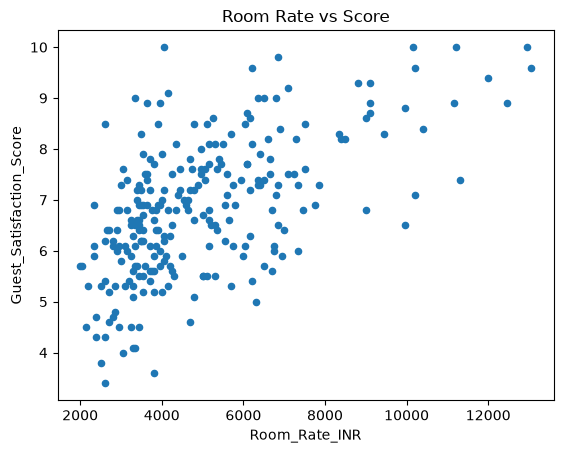

In [19]:
print(df["Room_Rate_INR"].corr(df["Guest_Satisfaction_Score"]))
print(df["Meal_Spend_INR"].corr(df["Guest_Satisfaction_Score"]))

df.plot(kind="scatter", x="Room_Rate_INR", y="Guest_Satisfaction_Score")
plt.title("Room Rate vs Score")
plt.savefig("../images/q2_rate_vs_score.png")
plt.show()

## Does the score differ by Hotel_City, Room_Type, Booking_Channel and Customer_Type? Compare the average score across the groups in each of these columns.

Hotel_City
Bengaluru    6.792982
Delhi        6.553571
Goa          6.975000
Jaipur       6.527273
Mumbai       7.083544
Name: Guest_Satisfaction_Score, dtype: float64 

Room_Type
Deluxe      7.155682
Standard    6.270769
Suite       8.237500
Name: Guest_Satisfaction_Score, dtype: float64 

Booking_Channel
Mobile_App      6.670667
Travel_Agent    6.954902
Walk_In         6.844444
Website         6.893814
Name: Guest_Satisfaction_Score, dtype: float64 

Customer_Type
Corporate     6.650820
Family        6.832308
Individual    6.925000
Name: Guest_Satisfaction_Score, dtype: float64


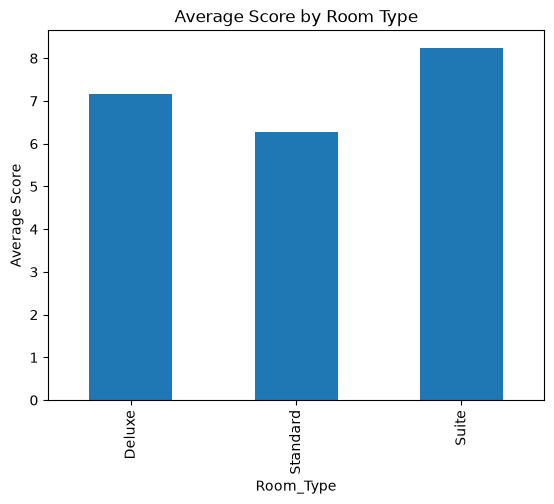

In [23]:
print(df.groupby("Hotel_City")["Guest_Satisfaction_Score"].mean(), "\n")
print(df.groupby("Room_Type")["Guest_Satisfaction_Score"].mean(), "\n")
print(df.groupby("Booking_Channel")["Guest_Satisfaction_Score"].mean(), "\n")
print(df.groupby("Customer_Type")["Guest_Satisfaction_Score"].mean())

df.groupby("Room_Type")["Guest_Satisfaction_Score"].mean().plot(kind="bar")
plt.title("Average Score by Room Type")
plt.ylabel("Average Score")
plt.savefig("../images/q3_score_by_room_type.png")
plt.show()

## Which bookings need attention? Label a booking “At Risk” if its Guest_Satisfaction_Score is below 5.5, then see how many there are and what they have in common.

Risk_Flag
OK         215
At Risk     35
Name: count, dtype: int64


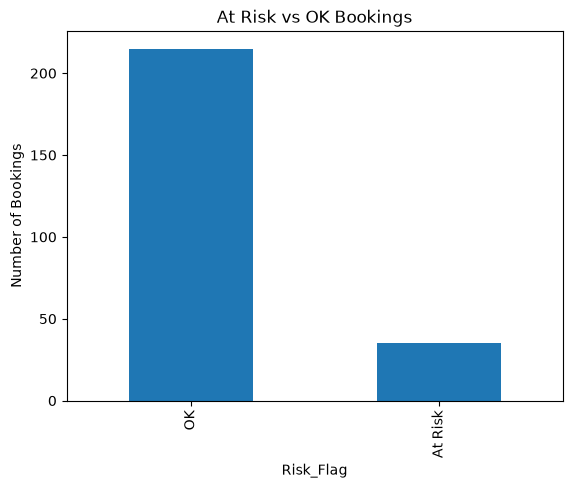

In [21]:
print(df["Risk_Flag"].value_counts())

df["Risk_Flag"].value_counts().plot(kind="bar")
plt.title("At Risk vs OK Bookings")
plt.ylabel("Number of Bookings")
plt.savefig("../images/q4_at_risk_count.png")
plt.show()